In [51]:
from langgraph.graph import StateGraph,START, END
from typing import TypedDict
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod


In [52]:
class MyState(TypedDict):
  height: float
  weight: float
  bmi: float
  condition: str

In [53]:
graph = StateGraph(MyState)

In [54]:
def calculate_bmi(state: MyState) -> MyState:
  height = state['height'] 
  weight = state['weight']
  bmi = weight / height ** 2
  return {
    "bmi": bmi
  }

In [55]:
def tell_condition(state: MyState) -> MyState:
  bmi = state['bmi']
  if bmi < 18.5:
    condition = "underweight"
  elif bmi < 25:
    condition = "normal weight"
  elif bmi < 30:
    condition = "overweight"
  else:
    condition = "obese"
  return {
    "condition": condition
  }

In [56]:
graph.add_node("calculate_bmi",calculate_bmi)
graph.add_node("tell_condition",tell_condition)

graph.add_edge(START, "calculate_bmi")
graph.add_edge("calculate_bmi", "tell_condition")
graph.add_edge("tell_condition", END)

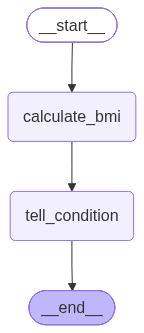

In [57]:
from IPython.display import Image, display

display(
    Image(
        workflow.get_graph().draw_mermaid_png()
    )
)

In [58]:
workflow  = graph.compile()

In [59]:
workflow.invoke({
  "height": 1.75, "weight": 70
})

{'height': 1.75,
 'weight': 70,
 'bmi': 22.857142857142858,
 'condition': 'normal weight'}